## Membaca CSV

In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = Path("raw_dataset.csv")
df = pd.read_csv(CSV_PATH)

metrics = [
    "throughput_mbps",
    "latency_ms",
    "jitter_ms",
    "packet_loss_percent",
    "cpu_client_percent",
    "cpu_server_percent",
]
group_cols = ["packet_size_bytes", "target_rate", "condition"]
rate_order = {"10M": 10, "50M": 50, "100M": 100}
packet_sizes = [128, 512, 1024]

print("Jumlah baris:", len(df))
print("Kolom:", df.columns.tolist())
display(df.head())


Jumlah baris: 91
Kolom: ['experiment_id', 'packet_size_bytes', 'target_rate', 'condition', 'repeat', 'source', 'iperf_status', 'receiver_status', 'throughput_mbps', 'jitter_ms', 'packet_loss_percent', 'latency_ms', 'cpu_client_percent', 'cpu_server_percent', 'cpu_client_samples', 'cpu_server_samples', 'notes']


,experiment_id,packet_size_bytes,target_rate,condition,repeat,source,iperf_status,receiver_status,throughput_mbps,jitter_ms,packet_loss_percent,latency_ms,cpu_client_percent,cpu_server_percent,cpu_client_samples,cpu_server_samples,notes
0,3_128bytes_10mbps_BASELINE_repeat1,128,10M,BASELINE,1,original,0,0,8.00,0.170,0.0,1.4513,89.7606,51.5771,33,35,NaN
1,3_128bytes_10mbps_BASELINE_repeat2,128,10M,BASELINE,2,original,0,0,7.84,0.167,0.0,1.3673,89.1848,51.5143,33,35,NaN
2,3_128bytes_10mbps_BASELINE_repeat3,128,10M,BASELINE,3,original,0,0,7.61,0.196,0.0,1.4150,86.9333,51.0771,33,35,NaN
3,3_128bytes_10mbps_BASELINE_repeat4,128,10M,BASELINE,4,original,0,0,7.89,0.234,0.0,1.3958,88.0636,51.6371,33,35,NaN
4,3_128bytes_10mbps_BASELINE_repeat5,128,10M,BASELINE,5,original,0,0,7.80,0.160,0.0,1.3904,88.4273,51.5771,33,35,NaN


## Label untuk Bar

In [11]:
def add_bar_labels(ax, bars, decimals=2):
    """Tambahkan label nilai pada setiap batang, termasuk nilai nol."""
    values = [bar.get_height() for bar in bars]
    max_value = max([abs(v) for v in values] + [0])
    offset = max_value * 0.015 if max_value else 0.000001
    for bar, value in zip(bars, values):
        ax.annotate(
            f"{value:.{decimals}f}",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 3 if value >= 0 else -3),
            textcoords="offset points",
            ha="center",
            va="bottom" if value >= 0 else "top",
            fontsize=8,
            rotation=0,
        )

def plot_metric_by_packet(comparison_df, metric, ylabel, decimals=2, packet_loss=False):
    """Satu gambar terpisah untuk setiap ukuran paket."""
    for size in packet_sizes:
        data = comparison_df[comparison_df["packet_size_bytes"] == size].copy()
        data = data.sort_values("target_rate", key=lambda col: col.map(rate_order))
        x = list(range(len(data)))
        width = 0.35
        fig, ax = plt.subplots(figsize=(8, 5))
        bars_base = ax.bar([i-width/2 for i in x], data["BASELINE"], width, label="Baseline")
        bars_wg = ax.bar([i+width/2 for i in x], data["WIREGUARD"], width, label="WireGuard")
        add_bar_labels(ax, bars_base, decimals)
        add_bar_labels(ax, bars_wg, decimals)
        ax.set_xticks(x)
        ax.set_xticklabels(data["target_rate"])
        ax.set_title(f"{ylabel} - Ukuran Paket {size} byte")
        ax.set_xlabel("Target Bitrate")
        ax.set_ylabel(ylabel)
        if packet_loss:
            max_actual = max(float(data["BASELINE"].max()), float(data["WIREGUARD"].max()))
            upper = max_actual * 1.30 if max_actual > 0 else 0.0001
            ax.set_ylim(0, upper)
            ax.ticklabel_format(axis="y", style="plain", useOffset=False)
        ax.legend()
        ax.grid(axis="y", alpha=0.3)
        fig.tight_layout()
        plt.show()

## Pemisahan Analisis Berdasarkan Ukuran Paket dan Intensitas Trafik

In [12]:
def plot_factor_trends(comparison_df, metric, ylabel, decimals=2):
    """Grafik analisis terpisah: berdasarkan target trafik dan ukuran paket.
    Baseline dan WireGuard dibuat sebagai gambar terpisah agar tidak bertumpuk.
    """
    # A. Analisis berdasarkan intensitas trafik (ukuran paket menjadi seri garis).
    for condition in ["BASELINE", "WIREGUARD"]:
        fig, ax = plt.subplots(figsize=(8, 5))
        for size in packet_sizes:
            data = comparison_df[
                (comparison_df["condition"] == condition)
                & (comparison_df["packet_size_bytes"] == size)
            ].copy()
            data = data.sort_values("target_rate", key=lambda col: col.map(rate_order))
            x = [rate_order[r] for r in data["target_rate"]]
            y = data[metric].to_numpy()
            ax.plot(x, y, marker="o", label=f"{size} byte")
            for xv, yv in zip(x, y):
                ax.annotate(f"{yv:.{decimals}f}", (xv, yv), xytext=(0, 6),
                            textcoords="offset points", ha="center", fontsize=8)
        ax.set_title(f"Pengaruh Intensitas Trafik terhadap {ylabel} ({condition.title()})")
        ax.set_xlabel("Target Bitrate (Mbps)")
        ax.set_ylabel(ylabel)
        ax.set_xticks([10, 50, 100])
        ax.legend(title="Ukuran Paket")
        ax.grid(alpha=0.3)
        fig.tight_layout()
        plt.show()

    # B. Analisis berdasarkan ukuran paket (target trafik menjadi seri garis).
    for condition in ["BASELINE", "WIREGUARD"]:
        fig, ax = plt.subplots(figsize=(8, 5))
        for rate in ["10M", "50M", "100M"]:
            data = comparison_df[
                (comparison_df["condition"] == condition)
                & (comparison_df["target_rate"] == rate)
            ].copy().sort_values("packet_size_bytes")
            x = data["packet_size_bytes"].to_numpy()
            y = data[metric].to_numpy()
            ax.plot(x, y, marker="o", label=f"{rate}")
            for xv, yv in zip(x, y):
                ax.annotate(f"{yv:.{decimals}f}", (xv, yv), xytext=(0, 6),
                            textcoords="offset points", ha="center", fontsize=8)
        ax.set_title(f"Pengaruh Ukuran Paket terhadap {ylabel} ({condition.title()})")
        ax.set_xlabel("Ukuran Paket (byte)")
        ax.set_ylabel(ylabel)
        ax.set_xticks(packet_sizes)
        ax.legend(title="Target Bitrate")
        ax.grid(alpha=0.3)
        fig.tight_layout()
        plt.show()

## Memeriksa Status Pengujian dan Nilai Kosong

In [13]:
# Pastikan kolom tersedia
print("Kolom metrik yang tersedia:")
print([col for col in metrics if col in df.columns])

for column, label in [
    ("iperf_status", "Status iperf3"),
    ("receiver_status", "Status receiver"),
    ("source", "Sumber data"),
]:
    print(f"\n{label}:")
    print(df[column].value_counts(dropna=False))

print("\nJumlah nilai kosong:")
print(df[metrics].isna().sum())


Kolom metrik yang tersedia:
['throughput_mbps', 'latency_ms', 'jitter_ms', 'packet_loss_percent', 'cpu_client_percent', 'cpu_server_percent']

Status iperf3:
iperf_status
0    90
1     1
Name: count, dtype: int64

Status receiver:
receiver_status
0    90
1     1
Name: count, dtype: int64

Sumber data:
source
original    90
retest       1
Name: count, dtype: int64

Jumlah nilai kosong:
throughput_mbps        1
latency_ms             0
jitter_ms              1
packet_loss_percent    1
cpu_client_percent     0
cpu_server_percent     0
dtype: int64


## Data Valid

In [14]:
# Data valid harus memiliki status berhasil dan seluruh metrik utama.
valid_mask = (
    df["iperf_status"].eq(0)
    & df["receiver_status"].eq(0)
    & df[metrics].notna().all(axis=1)
)
df_valid = df.loc[valid_mask].copy()

print("Total data mentah:", len(df))
print("Data valid:", len(df_valid))
print("Data dikecualikan:", len(df) - len(df_valid))

print("\nData valid berdasarkan kondisi:")
print(df_valid.groupby(["condition", "source"]).size())

print("\nData yang dikecualikan:")
display(df.loc[~valid_mask])


Total data mentah: 91
Data valid: 90
Data dikecualikan: 1

Data valid berdasarkan kondisi:
condition  source  
BASELINE   original    44
           retest       1
WIREGUARD  original    45
dtype: int64

Data yang dikecualikan:


,experiment_id,packet_size_bytes,target_rate,condition,repeat,source,iperf_status,receiver_status,throughput_mbps,jitter_ms,packet_loss_percent,latency_ms,cpu_client_percent,cpu_server_percent,cpu_client_samples,cpu_server_samples,notes
64,3_1024bytes_10mbps_BASELINE_repeat5,1024,10M,BASELINE,5,original,1,1,NaN,NaN,NaN,1.5159,19.0727,17.46,33,35,iperf3 status missing/failed; receiver missing...


## Tabel Statistik

In [15]:
# Agregat mean dipakai bersama oleh tabel perbandingan dan grafik.
mean_by_condition = df_valid.groupby(group_cols)[metrics].mean()
stats_by_condition = df_valid.groupby(group_cols)[metrics].agg(
    ["count", "mean", "std", "min", "max"]
)

summary = df_valid.groupby(group_cols)[metrics].agg(["mean", "std"]).round(4)
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
display(summary.reset_index())


,packet_size_bytes,target_rate,condition,throughput_mbps_mean,throughput_mbps_std,latency_ms_mean,latency_ms_std,jitter_ms_mean,jitter_ms_std,packet_loss_percent_mean,packet_loss_percent_std,cpu_client_percent_mean,cpu_client_percent_std,cpu_server_percent_mean,cpu_server_percent_std
0,128,100M,BASELINE,7.668,0.4905,1.2907,0.0355,0.1732,0.0116,0.0000,0.0000,86.7909,3.3536,50.6486,0.5025
1,128,100M,WIREGUARD,4.278,0.2235,94.3631,5.1461,29.3198,25.1093,0.0000,0.0000,88.4854,0.4371,50.7594,1.0364
2,128,10M,BASELINE,7.828,0.1431,1.4040,0.0315,0.1854,0.0304,0.0000,0.0000,88.4739,1.0845,51.4765,0.2275
3,128,10M,WIREGUARD,4.272,0.1062,96.1429,3.7383,11.7608,12.3453,0.0000,0.0000,88.5315,0.3699,51.1692,0.6605
4,128,50M,BASELINE,8.058,0.1865,1.4242,0.2063,0.2200,0.0394,0.0000,0.0000,89.5279,0.2801,51.1000,0.4231
5,128,50M,WIREGUARD,1.222,0.0045,318.0010,1.7068,0.6292,0.0641,0.0000,0.0000,65.9843,0.9566,39.3257,0.8898
6,512,100M,BASELINE,32.480,0.3033,1.3560,0.0665,0.1650,0.0087,0.0000,0.0000,89.6036,0.1531,51.1594,0.2174
7,512,100M,WIREGUARD,4.784,0.0329,326.2288,2.1092,0.6810,0.0982,0.0000,0.0000,64.4885,1.0108,39.2926,0.6830
8,512,10M,BASELINE,9.706,0.2060,1.8962,1.2205,0.2816,0.0355,0.0003,0.0006,51.9352,0.7422,45.0629,1.0561
9,512,10M,WIREGUARD,4.862,0.0492,319.1124,3.6809,0.7332,0.1100,0.0000,0.0000,65.6988,0.8673,39.4177,0.2428


## Persentase Perubahan

In [16]:
# Bandingkan rata-rata WireGuard dengan Baseline untuk seluruh metrik.
comparison = mean_by_condition.unstack("condition")
percent_change = (
    (comparison.xs("WIREGUARD", axis=1, level=1)
     - comparison.xs("BASELINE", axis=1, level=1))
    / comparison.xs("BASELINE", axis=1, level=1).abs()
) * 100
percent_change = percent_change.reset_index()
display(percent_change.round(2))


,packet_size_bytes,target_rate,throughput_mbps,latency_ms,jitter_ms,packet_loss_percent,cpu_client_percent,cpu_server_percent
0,128,100M,-44.21,7211.11,16828.29,NaN,1.95,0.22
1,128,10M,-45.43,6747.98,6243.47,NaN,0.07,-0.60
2,128,50M,-84.83,22229.02,186.00,NaN,-26.30,-23.04
3,512,100M,-85.27,23958.17,312.73,NaN,-28.03,-23.20
4,512,10M,-49.91,16728.69,160.37,-100.0,26.50,-12.53
5,512,50M,-39.12,7244.83,6412.59,NaN,9.05,1.31
6,1024,100M,-42.65,3937.41,6986.87,NaN,2.30,0.86
7,1024,10M,-0.06,125.49,78.79,NaN,30.86,-9.43
8,1024,50M,-79.13,12289.76,185.24,NaN,-13.67,-19.82


## Throughput

In [17]:
# Sajikan perbandingan throughput dari agregat yang sudah dihitung.
throughput_comparison = mean_by_condition["throughput_mbps"].unstack("condition").reset_index()
throughput_comparison["diff_mbps"] = (
    throughput_comparison["WIREGUARD"] - throughput_comparison["BASELINE"]
)
throughput_comparison["change_percent"] = (
    throughput_comparison["diff_mbps"]
    / throughput_comparison["BASELINE"].abs()
    * 100
)
display(throughput_comparison.round(2))


condition,packet_size_bytes,target_rate,BASELINE,WIREGUARD,diff_mbps,change_percent
0,128,100M,7.67,4.28,-3.39,-44.21
1,128,10M,7.83,4.27,-3.56,-45.43
2,128,50M,8.06,1.22,-6.84,-84.83
3,512,100M,32.48,4.78,-27.70,-85.27
4,512,10M,9.71,4.86,-4.84,-49.91
5,512,50M,27.60,16.80,-10.80,-39.12
6,1024,100M,59.28,34.00,-25.28,-42.65
7,1024,10M,9.98,9.97,-0.01,-0.06
8,1024,50M,46.70,9.74,-36.96,-79.13


In [18]:
# Statistik deskriptif throughput tersedia di summary; tampilkan kolom terkait saja.
display(
    stats_by_condition["throughput_mbps"]
    .round(4)
    .reset_index()
)


,packet_size_bytes,target_rate,condition,count,mean,std,min,max
0,128,100M,BASELINE,5,7.668,0.4905,6.94,8.09
1,128,100M,WIREGUARD,5,4.278,0.2235,4.04,4.54
2,128,10M,BASELINE,5,7.828,0.1431,7.61,8.00
3,128,10M,WIREGUARD,5,4.272,0.1062,4.16,4.39
4,128,50M,BASELINE,5,8.058,0.1865,7.82,8.27
5,128,50M,WIREGUARD,5,1.222,0.0045,1.22,1.23
6,512,100M,BASELINE,5,32.480,0.3033,32.00,32.80
7,512,100M,WIREGUARD,5,4.784,0.0329,4.76,4.82
8,512,10M,BASELINE,5,9.706,0.2060,9.41,9.93
9,512,10M,WIREGUARD,5,4.862,0.0492,4.78,4.90


In [19]:
display(
    df_valid.loc[
        (df_valid["packet_size_bytes"] == 512)
        & (df_valid["target_rate"] == "50M")
        & (df_valid["condition"] == "BASELINE"),
        [
            "experiment_id",
            "repeat",
            "source",
            "throughput_mbps",
            "latency_ms",
            "jitter_ms",
            "packet_loss_percent",
            "iperf_status",
            "receiver_status",
            "notes",
        ],
    ].sort_values(["repeat", "source"])
)

,experiment_id,repeat,source,throughput_mbps,latency_ms,jitter_ms,packet_loss_percent,iperf_status,receiver_status,notes
40,3_512bytes_50mbps_BASELINE_repeat1,1,original,6.98,1.3689,0.285,0.0,0,0,NaN
41,3_512bytes_50mbps_BASELINE_repeat2,2,original,33.10,1.2666,0.187,0.0,0,0,NaN
42,3_512bytes_50mbps_BASELINE_repeat3,3,original,32.60,1.3705,0.631,0.0,0,0,NaN
43,3_512bytes_50mbps_BASELINE_repeat4,4,original,33.10,1.3085,0.205,0.0,0,0,NaN
44,3_512bytes_50mbps_BASELINE_repeat5,5,original,32.20,1.3136,0.177,0.0,0,0,NaN


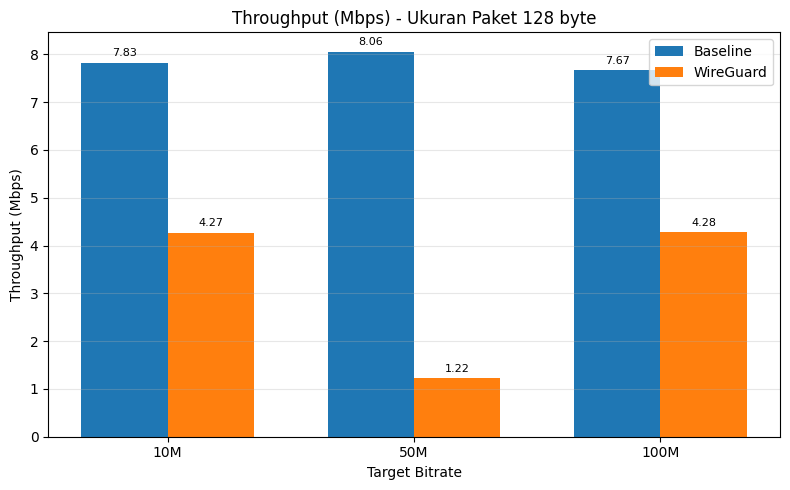

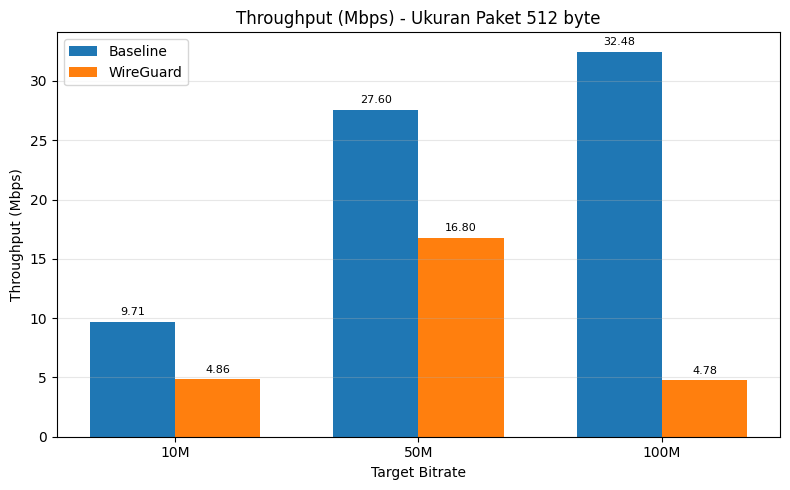

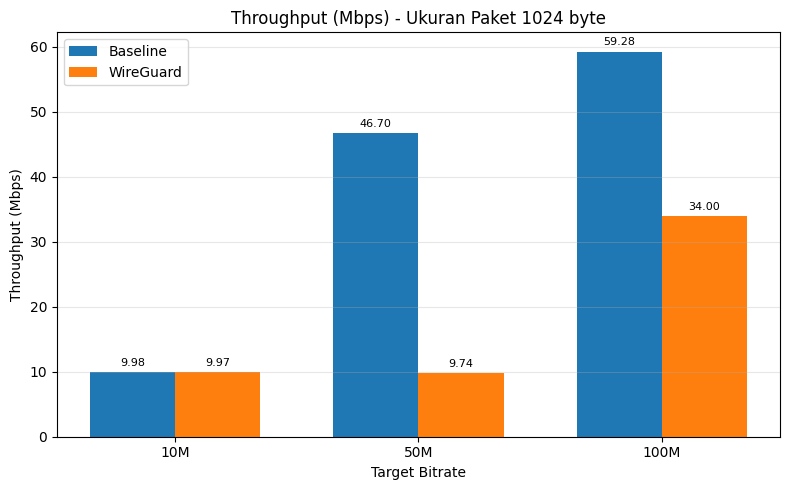

In [24]:
plot_metric_by_packet(throughput_comparison, "throughput_mbps", "Throughput (Mbps)", decimals=2)


## Latency

In [22]:
latency_stats = stats_by_condition["latency_ms"].round(4).reset_index()
display(latency_stats)


,packet_size_bytes,target_rate,condition,count,mean,std,min,max
0,128,100M,BASELINE,5,1.2907,0.0355,1.2349,1.3182
1,128,100M,WIREGUARD,5,94.3631,5.1461,88.8168,100.7196
2,128,10M,BASELINE,5,1.4040,0.0315,1.3673,1.4513
3,128,10M,WIREGUARD,5,96.1429,3.7383,91.2829,101.4815
4,128,50M,BASELINE,5,1.4242,0.2063,1.2491,1.7081
5,128,50M,WIREGUARD,5,318.0010,1.7068,315.9483,320.2600
6,512,100M,BASELINE,5,1.3560,0.0665,1.2808,1.4293
7,512,100M,WIREGUARD,5,326.2288,2.1092,322.9327,328.0986
8,512,10M,BASELINE,5,1.8962,1.2205,1.2837,4.0769
9,512,10M,WIREGUARD,5,319.1124,3.6809,316.2670,325.2692


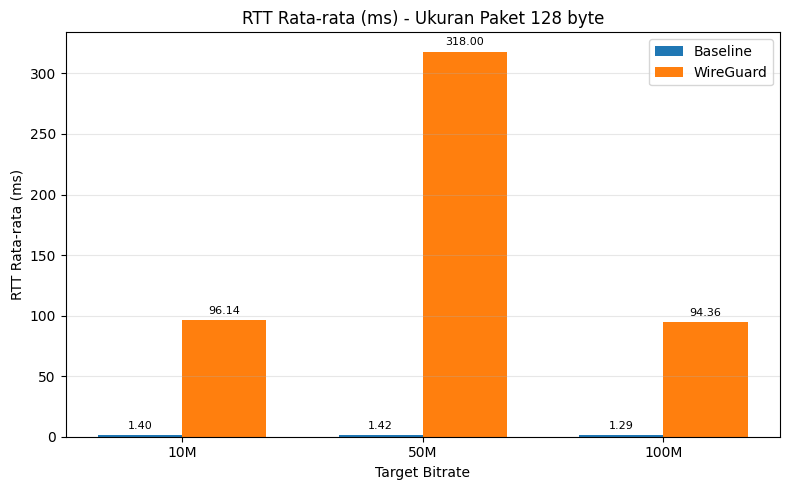

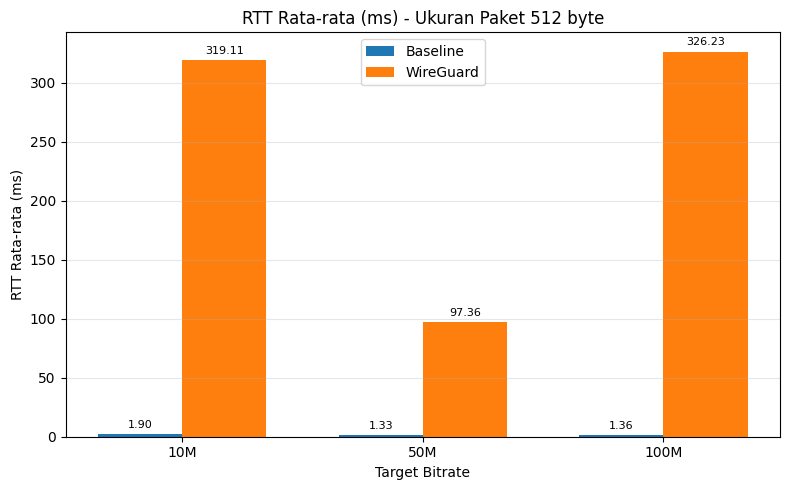

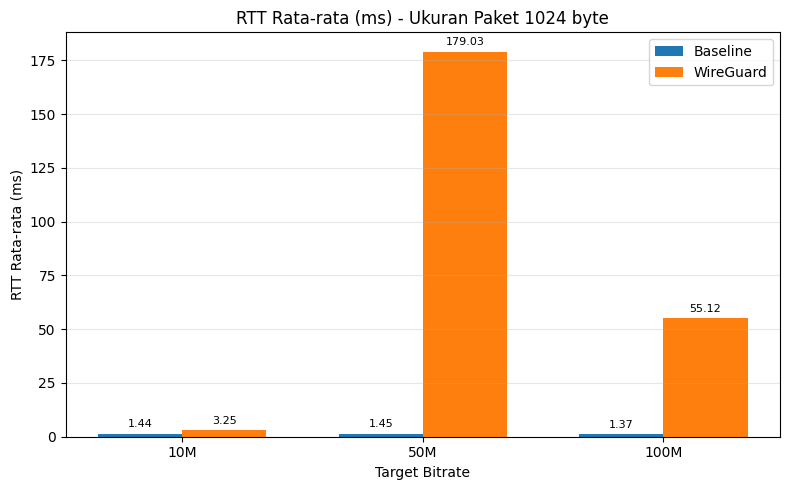

In [ ]:
latency_comparison = mean_by_condition["latency_ms"].unstack("condition").reset_index()
plot_metric_by_packet(latency_comparison, "latency_ms", "RTT Rata-rata (ms)", decimals=2)

## Jitter

In [ ]:
jitter_stats = stats_by_condition["jitter_ms"].round(4).reset_index()
display(jitter_stats)


,packet_size_bytes,target_rate,condition,count,mean,std,min,max
0,128,100M,BASELINE,5,0.1732,0.0116,0.161,0.186
1,128,100M,WIREGUARD,5,29.3198,25.1093,0.312,56.754
2,128,10M,BASELINE,5,0.1854,0.0304,0.160,0.234
3,128,10M,WIREGUARD,5,11.7608,12.3453,0.144,28.591
4,128,50M,BASELINE,5,0.2200,0.0394,0.177,0.282
5,128,50M,WIREGUARD,5,0.6292,0.0641,0.527,0.689
6,512,100M,BASELINE,5,0.1650,0.0087,0.151,0.174
7,512,100M,WIREGUARD,5,0.6810,0.0982,0.548,0.803
8,512,10M,BASELINE,5,0.2816,0.0355,0.242,0.332
9,512,10M,WIREGUARD,5,0.7332,0.1100,0.585,0.872


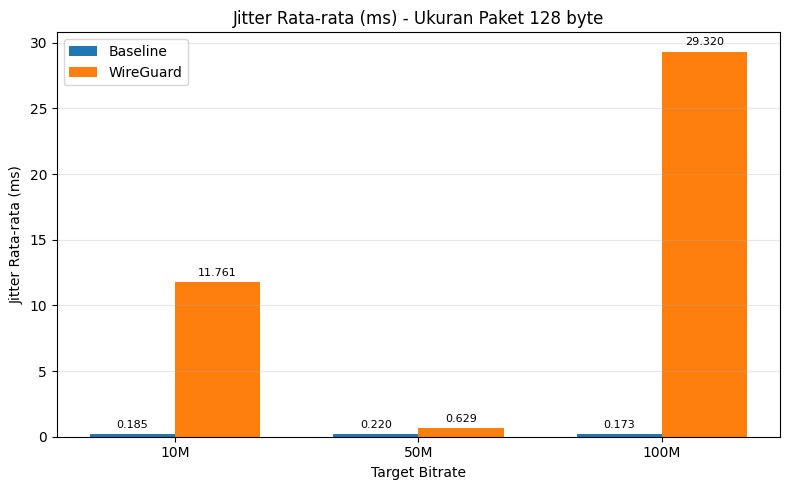

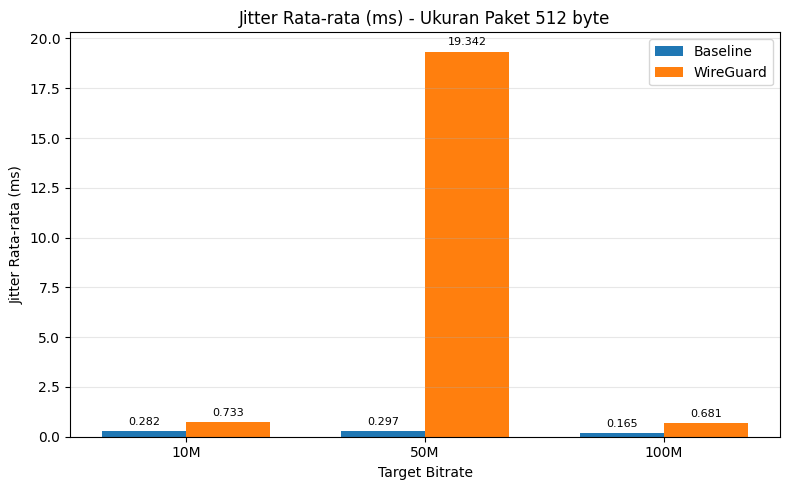

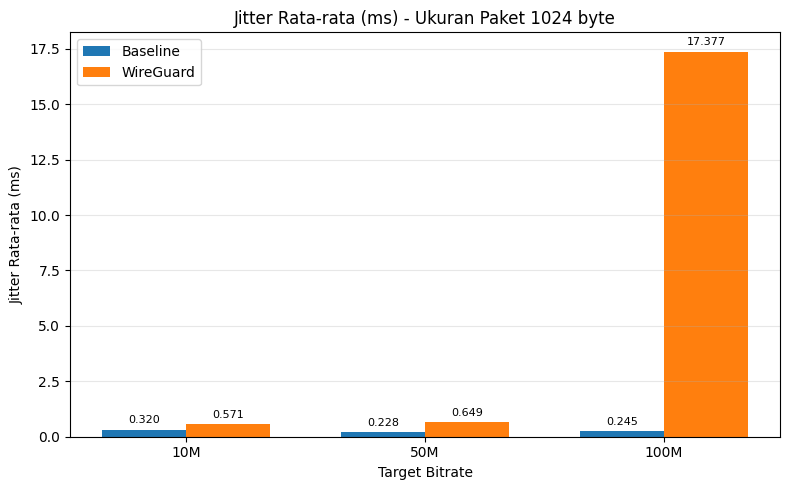

In [28]:
# Grafik jitter dipisahkan menjadi satu gambar untuk setiap ukuran paket.
jitter_comparison = mean_by_condition["jitter_ms"].unstack("condition").reset_index()
plot_metric_by_packet(jitter_comparison, "jitter_ms", "Jitter Rata-rata (ms)", decimals=3)


## Packet Loss

In [ ]:
packet_loss_stats = stats_by_condition["packet_loss_percent"].round(4).reset_index()
display(packet_loss_stats)

,packet_size_bytes,target_rate,condition,count,mean,std,min,max
0,128,100M,BASELINE,5,0.0000,0.0000,0.0,0.0000
1,128,100M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000
2,128,10M,BASELINE,5,0.0000,0.0000,0.0,0.0000
3,128,10M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000
4,128,50M,BASELINE,5,0.0000,0.0000,0.0,0.0000
5,128,50M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000
6,512,100M,BASELINE,5,0.0000,0.0000,0.0,0.0000
7,512,100M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000
8,512,10M,BASELINE,5,0.0003,0.0006,0.0,0.0014
9,512,10M,WIREGUARD,5,0.0000,0.0000,0.0,0.0000


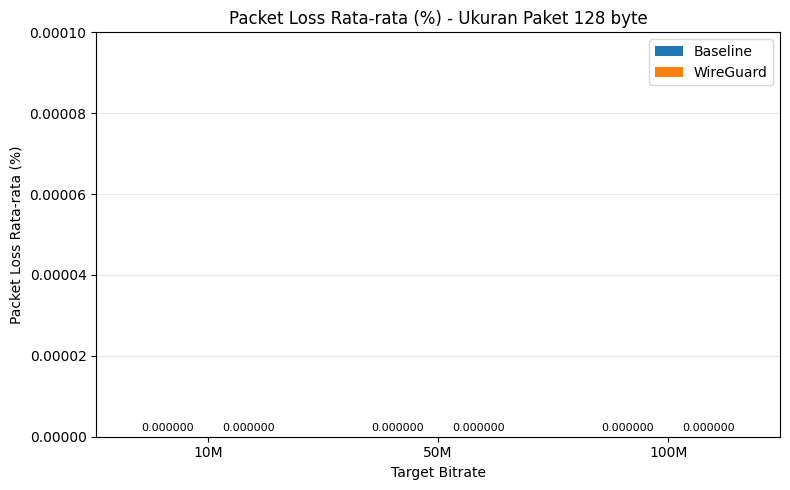

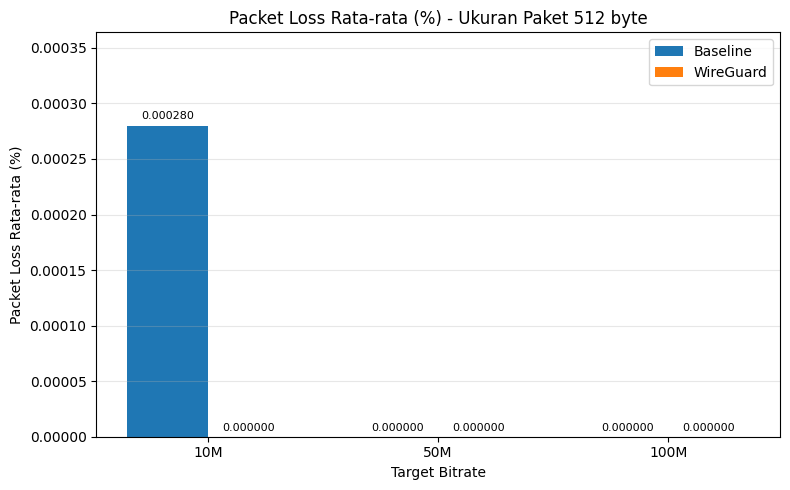

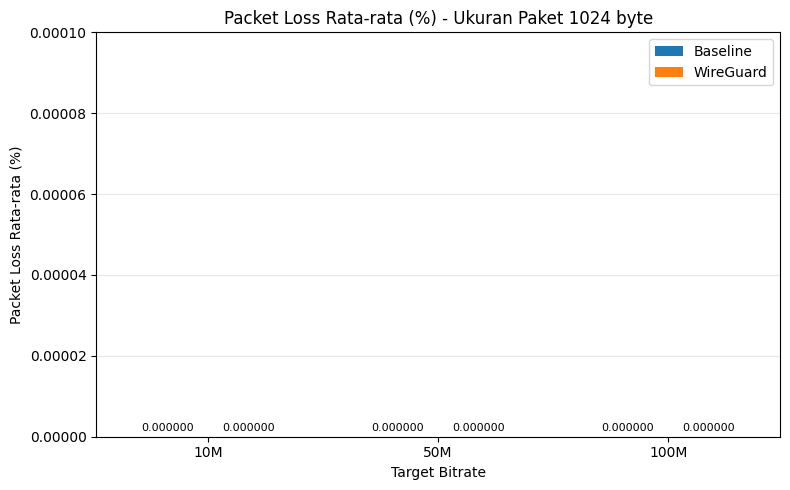

In [30]:
packet_loss_comparison = mean_by_condition["packet_loss_percent"].unstack("condition").reset_index()
plot_metric_by_packet(
    packet_loss_comparison,
    "packet_loss_percent",
    "Packet Loss Rata-rata (%)",
    decimals=6,
    packet_loss=True,
)

## CPU Statistik

In [ ]:
cpu_stats = (
    stats_by_condition[cpu_metrics := ["cpu_client_percent", "cpu_server_percent"]]
    .round(4)
)
cpu_stats.columns = [f"{metric}_{stat}" for metric, stat in cpu_stats.columns]
display(cpu_stats.reset_index())


,packet_size_bytes,target_rate,condition,cpu_client_percent_count,cpu_client_percent_mean,cpu_client_percent_std,cpu_client_percent_min,cpu_client_percent_max,cpu_server_percent_count,cpu_server_percent_mean,cpu_server_percent_std,cpu_server_percent_min,cpu_server_percent_max
0,128,100M,BASELINE,5,86.7909,3.3536,81.8030,89.7061,5,50.6486,0.5025,49.9857,51.1143
1,128,100M,WIREGUARD,5,88.4854,0.4371,88.1030,88.9636,5,50.7594,1.0364,49.3771,51.7143
2,128,10M,BASELINE,5,88.4739,1.0845,86.9333,89.7606,5,51.4765,0.2275,51.0771,51.6371
3,128,10M,WIREGUARD,5,88.5315,0.3699,88.0152,89.0455,5,51.1692,0.6605,50.0000,51.5486
4,128,50M,BASELINE,5,89.5279,0.2801,89.2909,89.9636,5,51.1000,0.4231,50.7800,51.7971
5,128,50M,WIREGUARD,5,65.9843,0.9566,64.9879,67.0212,5,39.3257,0.8898,37.8886,40.2057
6,512,100M,BASELINE,5,89.6036,0.1531,89.3606,89.7485,5,51.1594,0.2174,50.8600,51.4400
7,512,100M,WIREGUARD,5,64.4885,1.0108,63.3485,65.4879,5,39.2926,0.6830,38.3686,40.2857
8,512,10M,BASELINE,5,51.9352,0.7422,51.2697,53.1030,5,45.0629,1.0561,43.6286,46.3343
9,512,10M,WIREGUARD,5,65.6988,0.8673,64.5303,66.8545,5,39.4177,0.2428,39.0943,39.7343


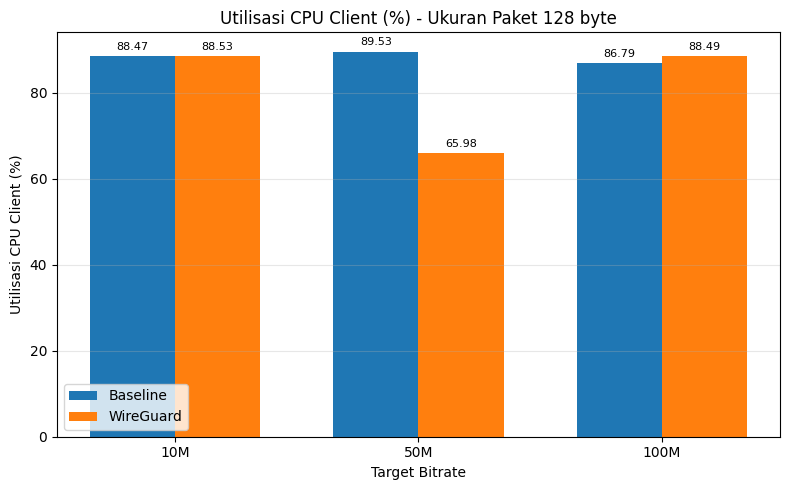

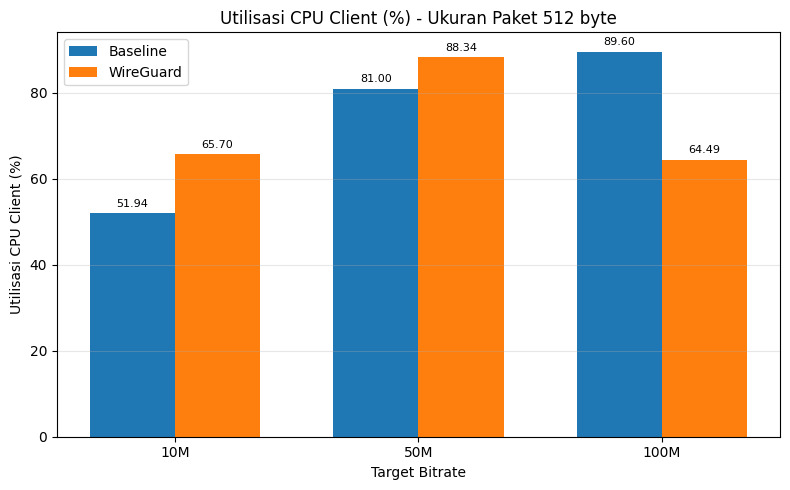

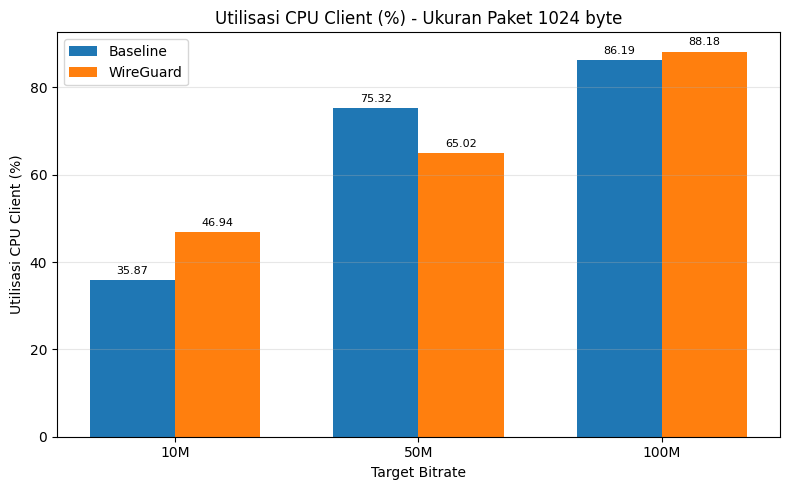

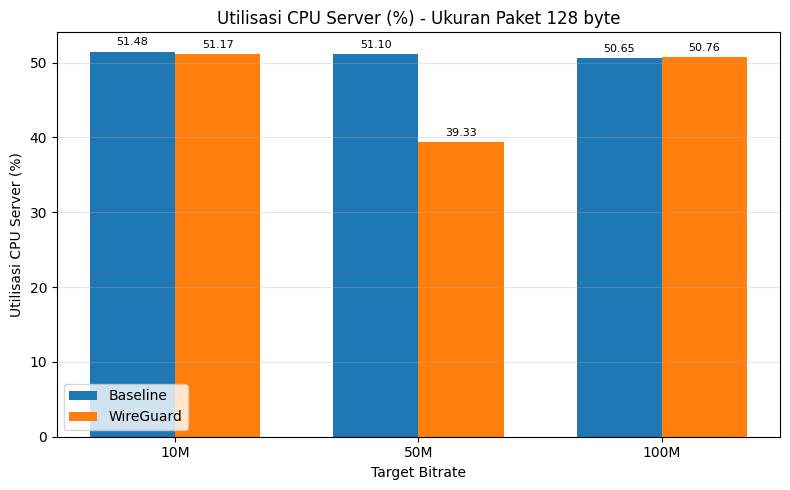

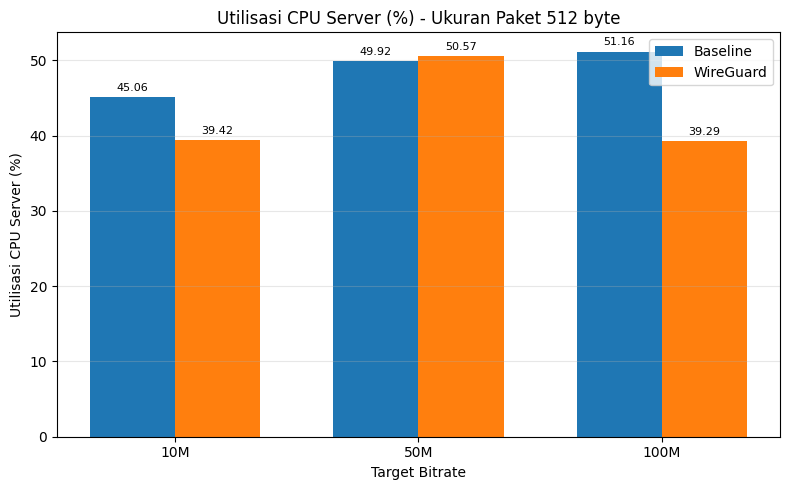

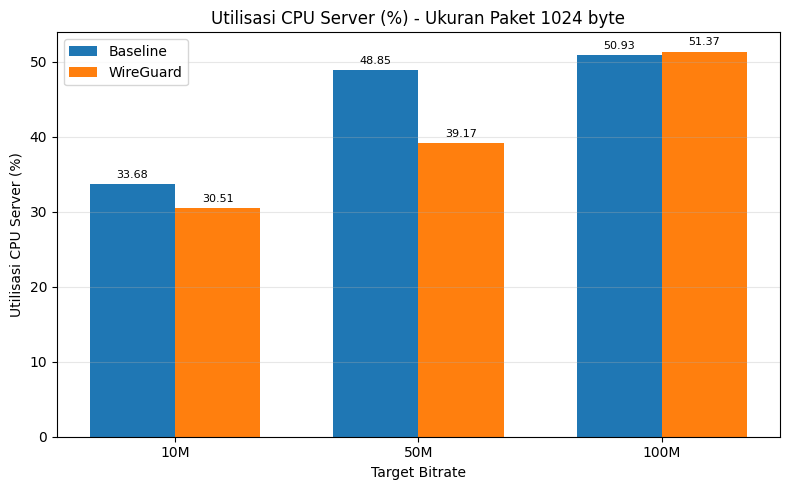

In [32]:
cpu_metrics = ["cpu_client_percent", "cpu_server_percent"]
cpu_comparison = mean_by_condition[cpu_metrics].reset_index()

for metric, title in [
    ("cpu_client_percent", "Utilisasi CPU Client (%)"),
    ("cpu_server_percent", "Utilisasi CPU Server (%)"),
]:
    for size in packet_sizes:
        data = cpu_comparison[cpu_comparison["packet_size_bytes"] == size].copy()
        data = data.sort_values("target_rate", key=lambda values: values.map(rate_order))
        baseline_data = data[data["condition"] == "BASELINE"]
        wg_data = data[data["condition"] == "WIREGUARD"]
        x = list(range(len(baseline_data)))
        width = 0.35
        fig, ax = plt.subplots(figsize=(8, 5))
        bars_base = ax.bar([i-width/2 for i in x], baseline_data[metric], width, label="Baseline")
        bars_wg = ax.bar([i+width/2 for i in x], wg_data[metric], width, label="WireGuard")
        add_bar_labels(ax, bars_base, decimals=2)
        add_bar_labels(ax, bars_wg, decimals=2)
        ax.set_xticks(x)
        ax.set_xticklabels(baseline_data["target_rate"])
        ax.set_title(f"{title} - Ukuran Paket {size} byte")
        ax.set_xlabel("Target Bitrate")
        ax.set_ylabel(title)
        ax.legend()
        ax.grid(axis="y", alpha=0.3)
        fig.tight_layout()
        plt.show()


## validasi

In [ ]:
# Pemeriksaan validasi tambahan untuk dataset yang sudah disaring.
print("Jumlah baris:", len(df_valid))
print("\nJumlah pengujian per kondisi:")
display(df_valid.groupby(["condition", "source"]).size())

print("\nJumlah nilai kosong:")
display(df_valid[metrics].isna().sum())

print("\nStatistik latency dan jitter per kondisi:")
display(
    df_valid.groupby("condition")[["latency_ms", "jitter_ms"]]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)


Jumlah baris: 90

Jumlah pengujian per kondisi:


condition  source  
BASELINE   original    44
           retest       1
WIREGUARD  original    45
dtype: int64


Jumlah nilai kosong:


throughput_mbps        0
latency_ms             0
jitter_ms              0
packet_loss_percent    0
cpu_client_percent     0
cpu_server_percent     0
dtype: int64


Statistik latency dan jitter per kondisi:


latency_ms                             jitter_ms                  \
                mean       std     min       max      mean      std    min   
condition                                                                    
BASELINE      1.4387    0.4171  1.2349    4.0769    0.2350   0.0973  0.151   
WIREGUARD   165.4022  119.6372  3.0340  328.0986    9.0071  17.4422  0.142   

                   
              max  
condition          
BASELINE    0.631  
WIREGUARD  62.361

In [ ]:
# Tampilkan pengujian WireGuard dengan latency tertinggi
wg_latency_extreme = (
    df_valid[df_valid["condition"] == "WIREGUARD"]
    .sort_values("latency_ms", ascending=False)
    [
        [
            "experiment_id",
            "packet_size_bytes",
            "target_rate",
            "repeat",
            "source",
            "latency_ms",
            "jitter_ms",
            "throughput_mbps",
            "packet_loss_percent"
        ]
    ]
    .head(10)
)

display(wg_latency_extreme)

,experiment_id,packet_size_bytes,target_rate,repeat,source,latency_ms,jitter_ms,throughput_mbps,packet_loss_percent
55,3_512bytes_100mbps_WIREGUARD_repeat1,512,100M,1,original,328.0986,0.662,4.76,0.0
56,3_512bytes_100mbps_WIREGUARD_repeat2,512,100M,2,original,327.7051,0.803,4.76,0.0
58,3_512bytes_100mbps_WIREGUARD_repeat4,512,100M,4,original,326.9955,0.548,4.76,0.0
59,3_512bytes_100mbps_WIREGUARD_repeat5,512,100M,5,original,325.4119,0.645,4.82,0.0
35,3_512bytes_10mbps_WIREGUARD_repeat1,512,10M,1,original,325.2692,0.872,4.78,0.0
57,3_512bytes_100mbps_WIREGUARD_repeat3,512,100M,3,original,322.9327,0.747,4.82,0.0
16,3_128bytes_50mbps_WIREGUARD_repeat2,128,50M,2,original,320.2600,0.527,1.22,0.0
36,3_512bytes_10mbps_WIREGUARD_repeat2,512,10M,2,original,319.1489,0.804,4.86,0.0
15,3_128bytes_50mbps_WIREGUARD_repeat1,128,50M,1,original,318.8807,0.689,1.22,0.0
39,3_512bytes_10mbps_WIREGUARD_repeat5,512,10M,5,original,318.5764,0.690,4.87,0.0


## Pengaruh Intensitas Trafik atau Ukuran Paket terhadap Parameter

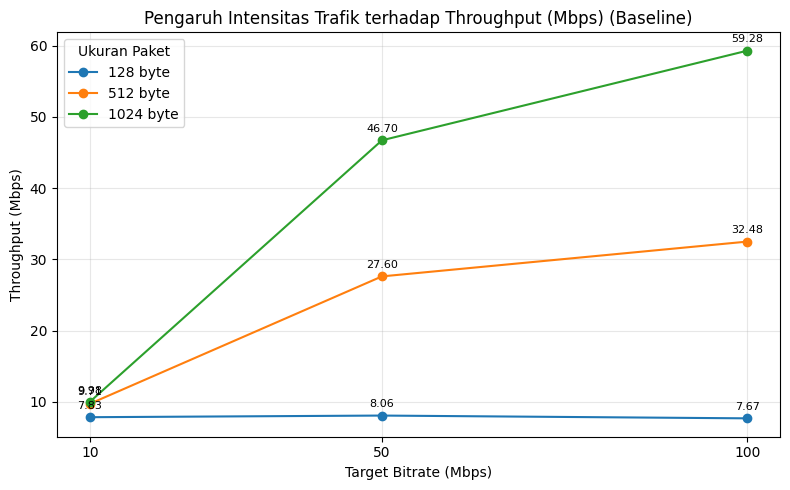

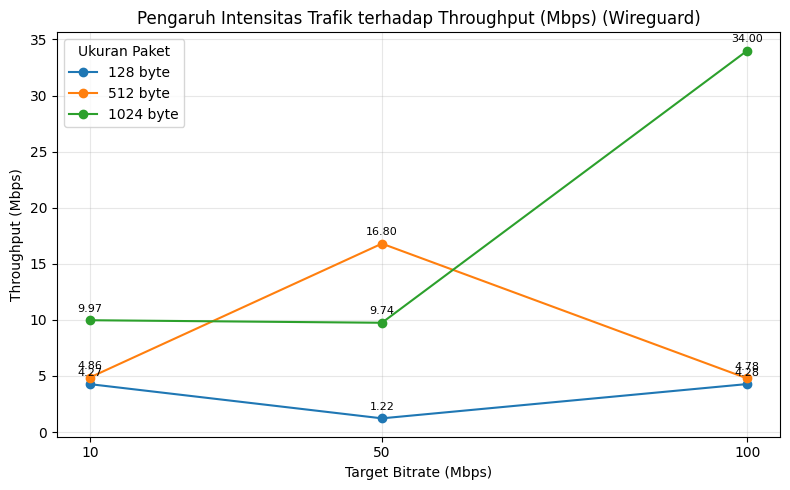

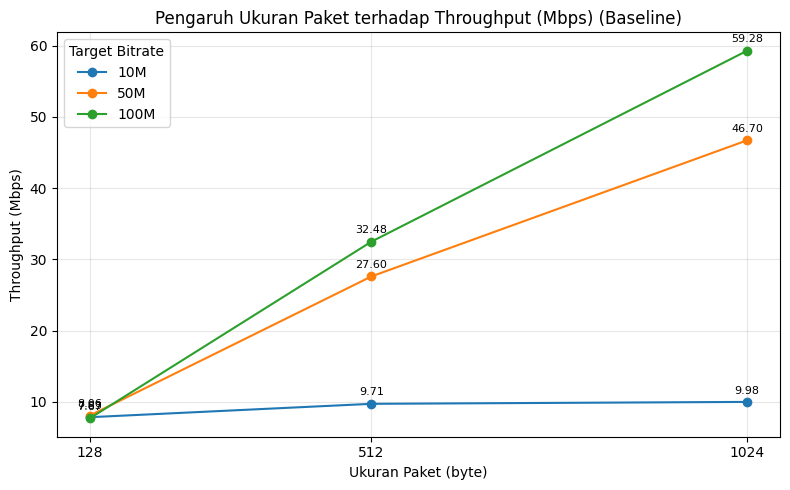

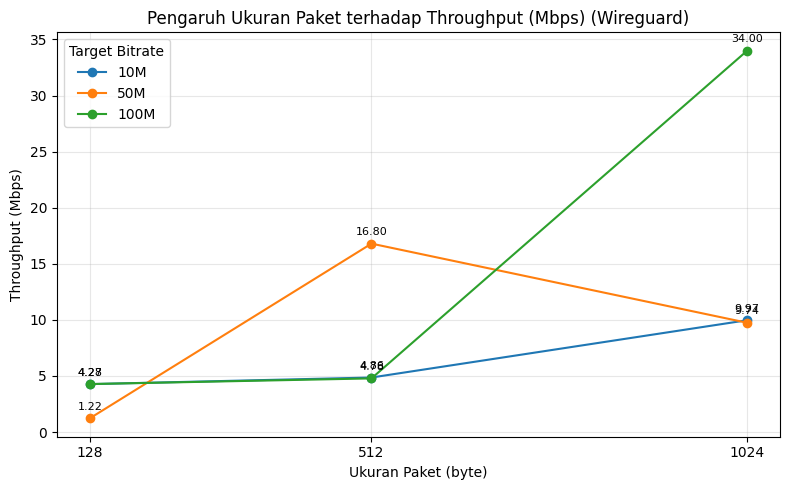

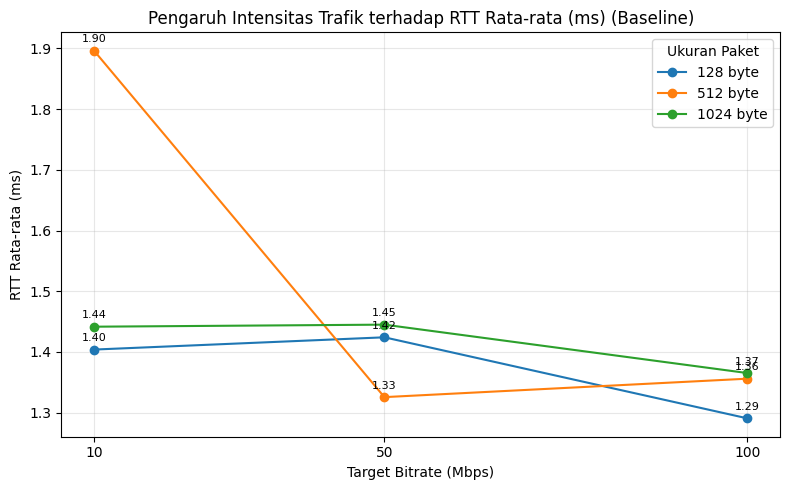

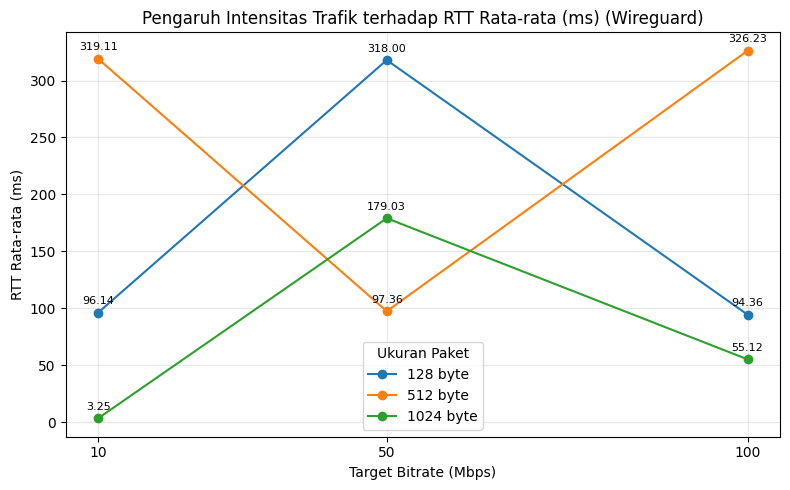

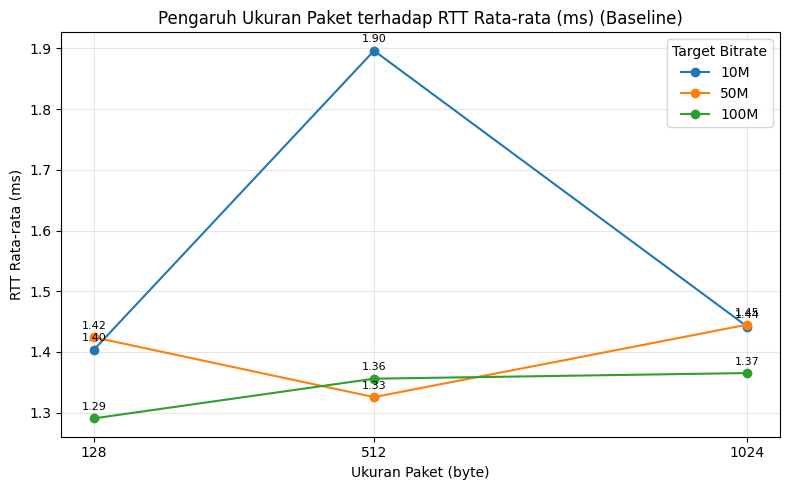

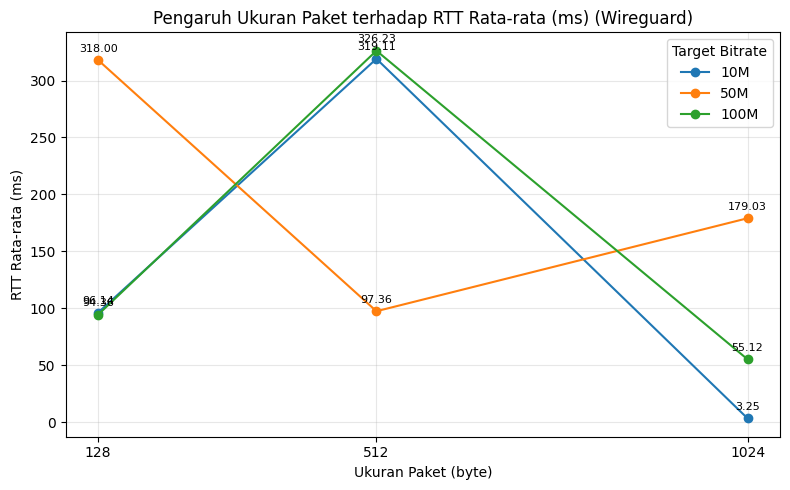

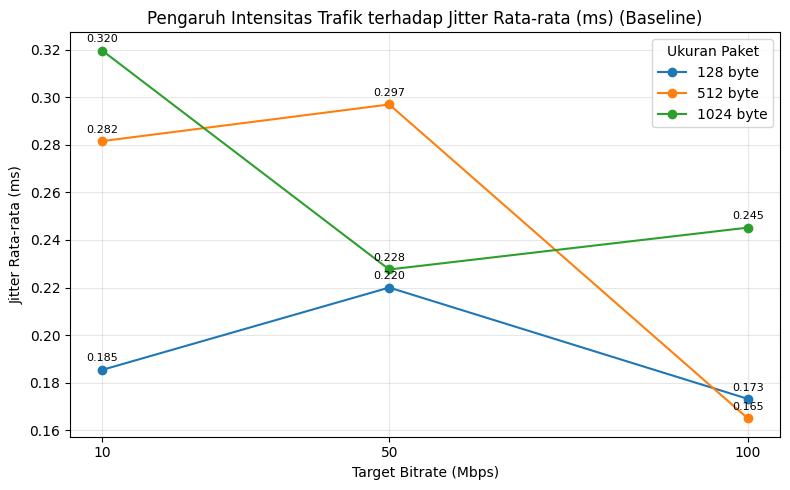

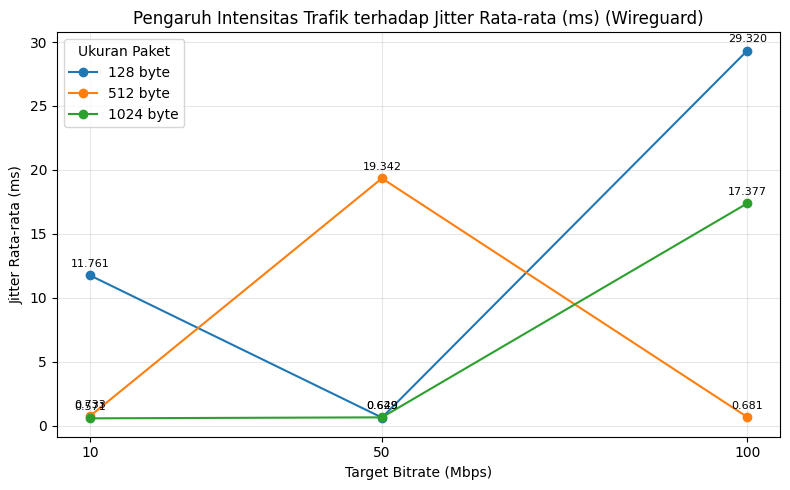

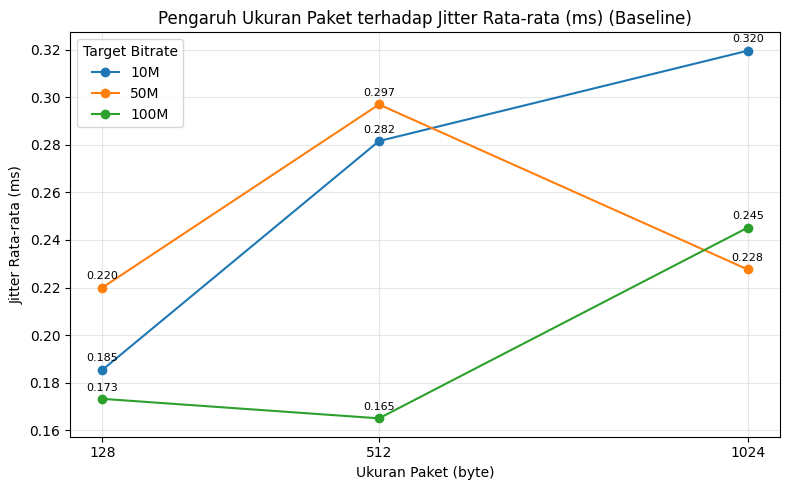

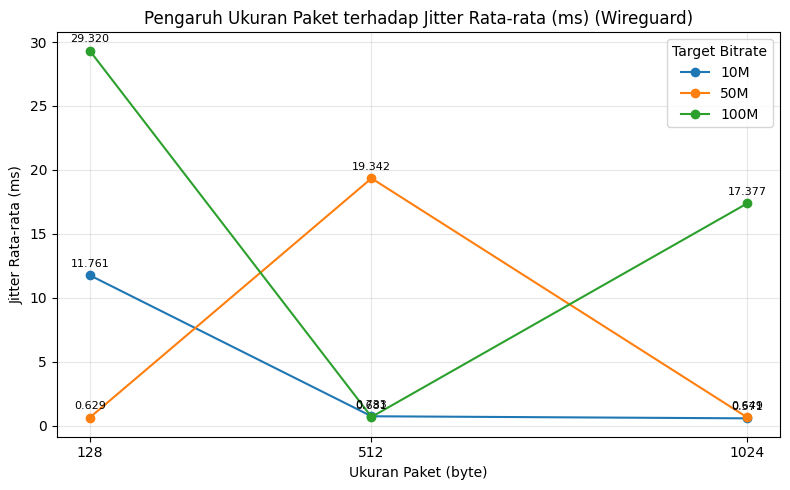

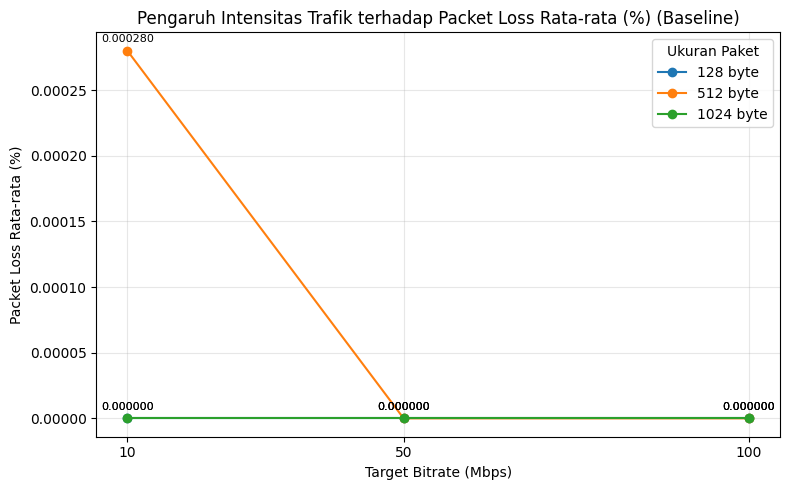

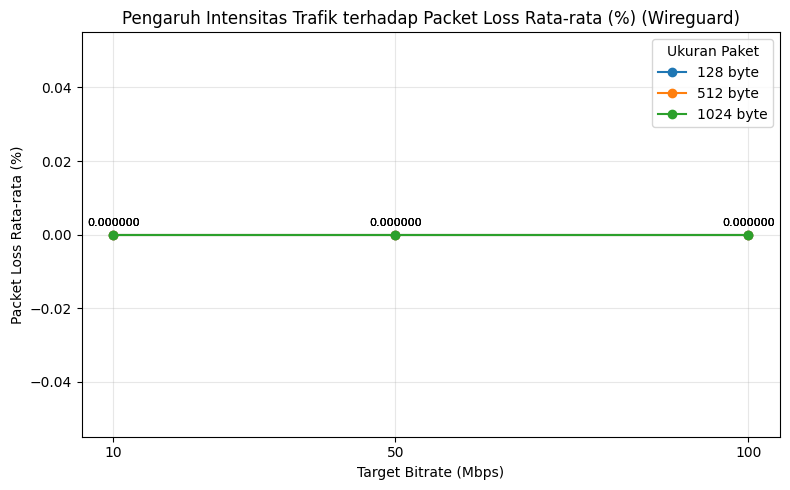

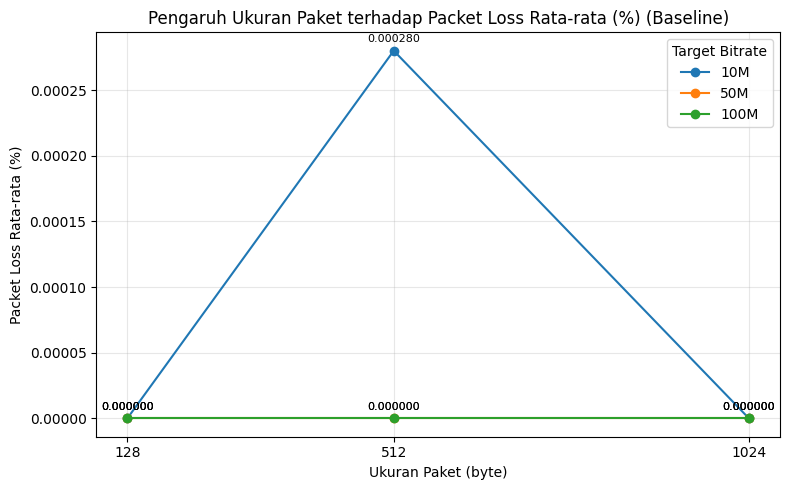

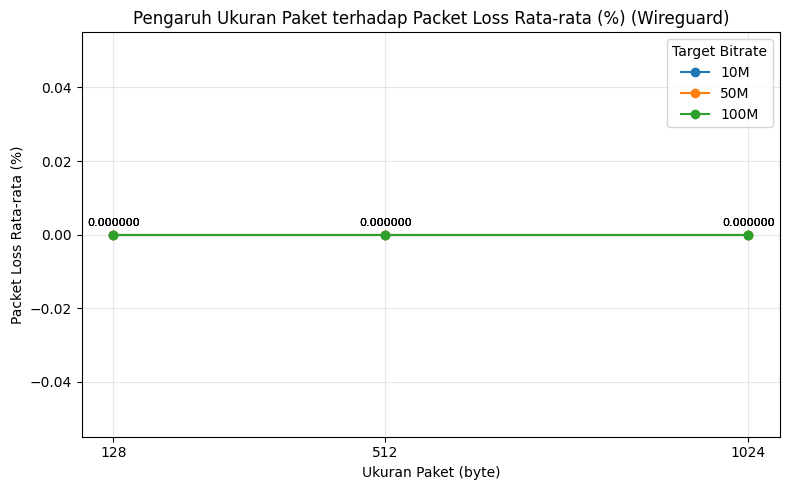

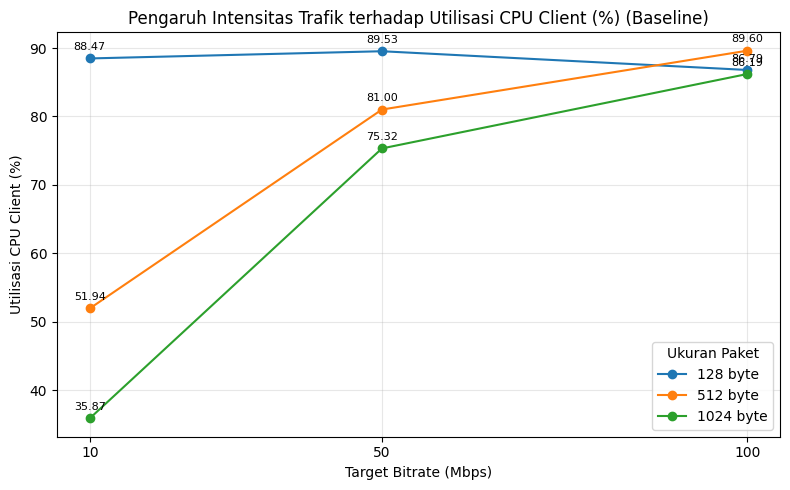

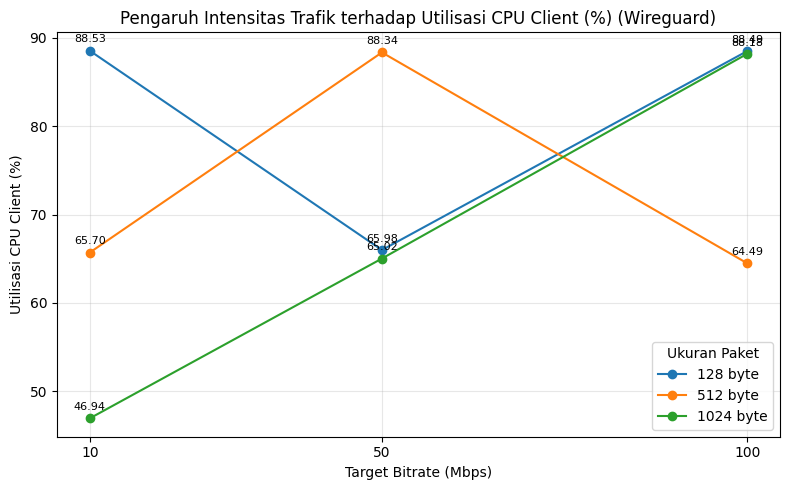

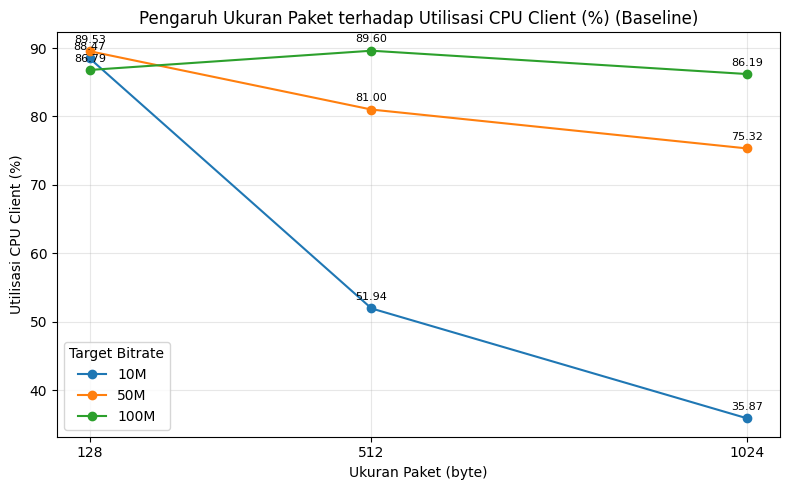

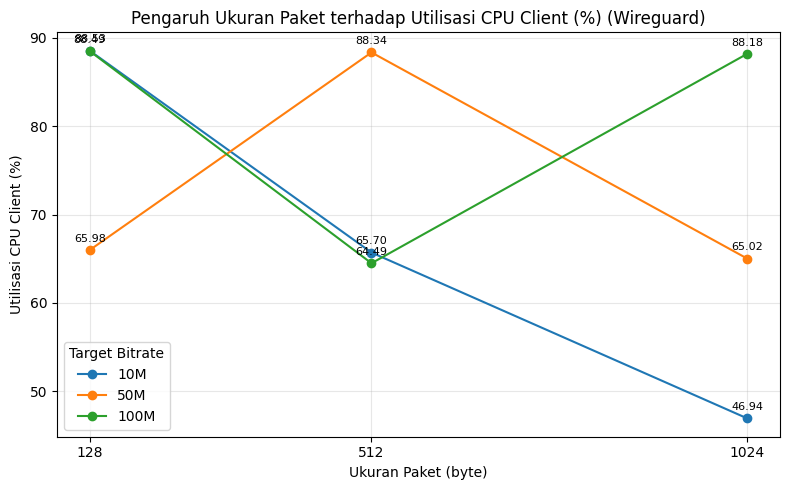

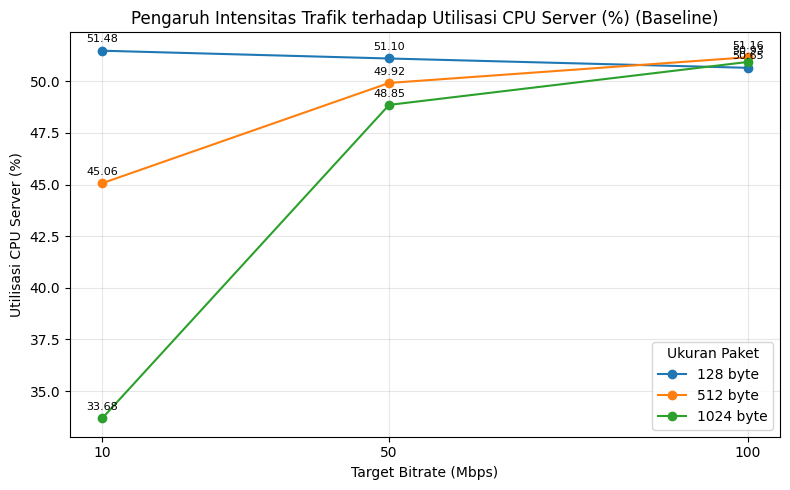

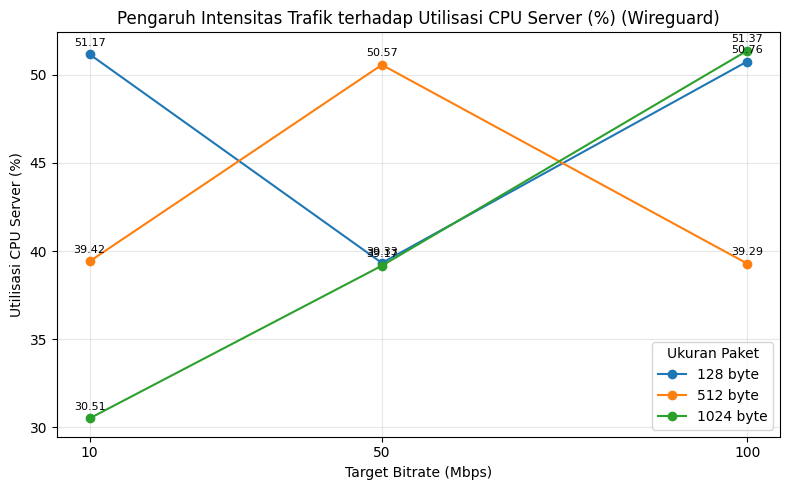

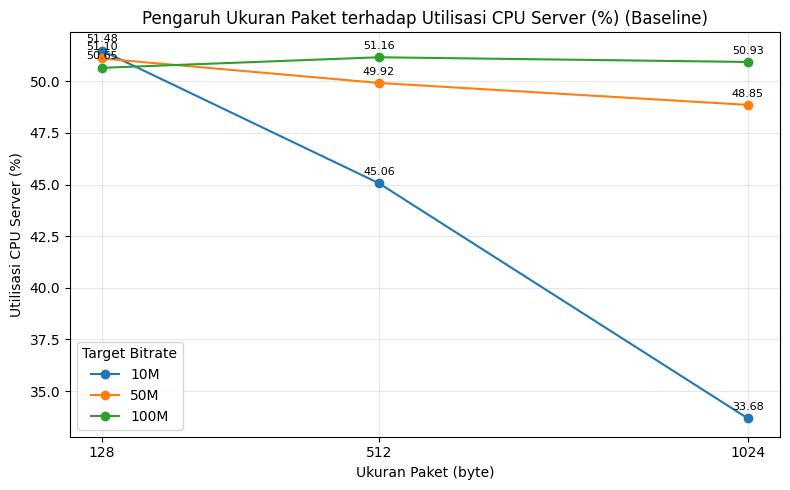

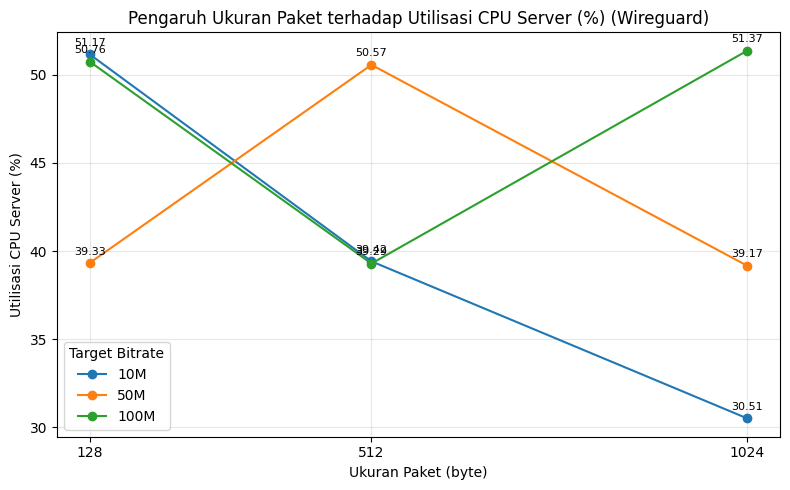

In [33]:
# Susun data rata-rata ke format kolom agar dapat dipakai pada grafik faktor.
factor_metrics = {
    "throughput_mbps": ("Throughput (Mbps)", 2),
    "latency_ms": ("RTT Rata-rata (ms)", 2),
    "jitter_ms": ("Jitter Rata-rata (ms)", 3),
    "packet_loss_percent": ("Packet Loss Rata-rata (%)", 6),
    "cpu_client_percent": ("Utilisasi CPU Client (%)", 2),
    "cpu_server_percent": ("Utilisasi CPU Server (%)", 2),
}

for metric, (ylabel, decimals) in factor_metrics.items():
    factor_comparison = mean_by_condition[metric].reset_index()
    plot_factor_trends(factor_comparison, metric, ylabel, decimals)